# HW3 — Human / AI / Fusion text classification

All logic is in `hw3_text_detection.py`; this notebook runs the pipeline stage by stage.
Runs on **Google Colab** and **locally** (VS Code) without changes: paths and device are detected automatically.

Heavy stages save their results to `runs/<name>/` on Google Drive. Set a toggle to `False`
to skip a stage and load its saved results instead.

## 0. Setup

In [11]:
# ---------------- toggles ----------------
RUN_EDA = True
RECOMPUTE_GROUPS = False   # cached in splits/groups.csv
RECOMPUTE_SPLIT = False    # cached in splits/split_v1.csv (always recomputed with new groups)
RUN_BASELINE = True        # False -> load runs/baseline_tfidf
RUN_ENCODER = False         # False -> load runs/encoder_xlmr_chunks

SUBSAMPLE_N = 40_000       # fixed subsample of whole groups; 20% of it is validation
BASELINE_RUN = "baseline_tfidf"
ENCODER_RUN = "encoder_xlmr_chunks"

# ---------------- environment ----------------
REPO_URL = "https://github.com/Rein-h/pavlunyshyn_hw3_AI"   # <- your repository
LOCAL_ROOT = r"G:\My Drive\hw3"                    # local run only: folder that contains data/

In [12]:
import os, sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    REPO_DIR = "/content/" + REPO_URL.rstrip("/").split("/")[-1].removesuffix(".git")
    if os.path.exists(REPO_DIR):
        !git -C {REPO_DIR} pull -q
    else:
        !git clone -q {REPO_URL} {REPO_DIR}
    %pip install -q -r {REPO_DIR}/requirements.txt
    sys.path.insert(0, REPO_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import hw3_text_detection as hw
importlib.reload(hw)  # picks up a new version of the .py after git pull

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
hw.seed_everything(hw.SEED)
RECOMPUTE_SPLIT = RECOMPUTE_SPLIT or RECOMPUTE_GROUPS

ENC_CFG = hw.EncoderConfig(
    model_name="xlm-roberta-base",
    max_len=512,          # tokens per window
    overlap=64,           # overlap of neighbouring windows
    train_windows=1,      # random windows per text per epoch
    max_eval_windows=8,   # windows averaged per text at inference
    epochs=2,
    lr=2e-5,
)

paths = hw.get_paths(local_root=LOCAL_ROOT, colab_root="/content/drive/MyDrive/hw3")
hw.describe_environment()

{'colab': True,
 'python': '3.13.16',
 'torch': '2.14.1+cu130',
 'device': 'cuda',
 'gpu': 'Tesla T4',
 'gpu_mem_gb': 14.6}

## 1. Data

In [14]:
train, test, sample = hw.load_data(paths)
hw.data_overview(train, test, sample)

,train,test
rows,272352,25000
unique ids,272352,25000
empty texts,0,0
duplicated texts (within set),0,0
texts also in other set,0,0
missing values,0,0
sample_submission ids == test ids (same order),1,


## 2. EDA
### 2.1 Class balance by language and domain

,count,share
label,,
human,66730,0.245
ai,121940,0.448
fusion,83682,0.307


label,human,ai,fusion
lang,,,
de-DE,14510,20337,17924
en-EN,52220,101603,65758


label                         human     ai  fusion
domain                 lang                       
arxiv_papers           en-EN    407  12050    1833
blog_authorship_corpus en-EN  12466  15684   12397
bundestag              de-DE  14479  19977   17887
cnn_news               en-EN  13395  19488   11402
euro_court_cases       en-EN   6277  11141   10160
gutenberg              de-DE     31    360      37
                       en-EN    216   6359     341
house_of_commons       en-EN   6953  15298    9608
student_essays         en-EN  12506  21583   20017

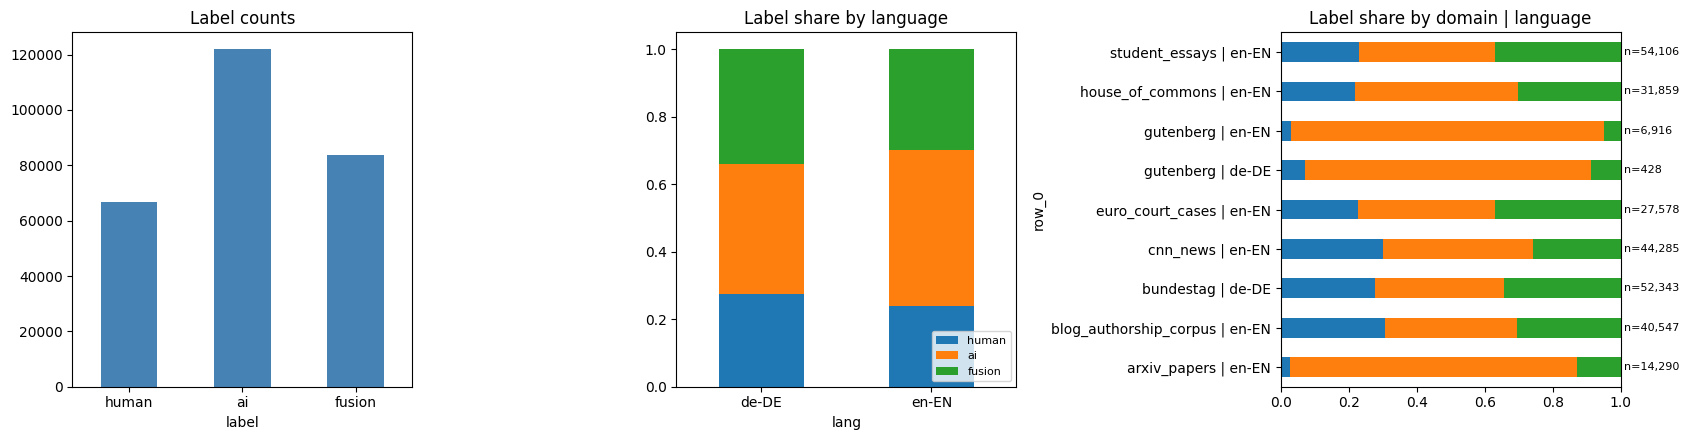

In [15]:
if RUN_EDA:
    tables = hw.class_balance_tables(train)
    display(tables["label"], tables["lang x label"], tables["domain x label"])
    hw.plot_class_balance(train)
    plt.show()

### 2.2 Text lengths

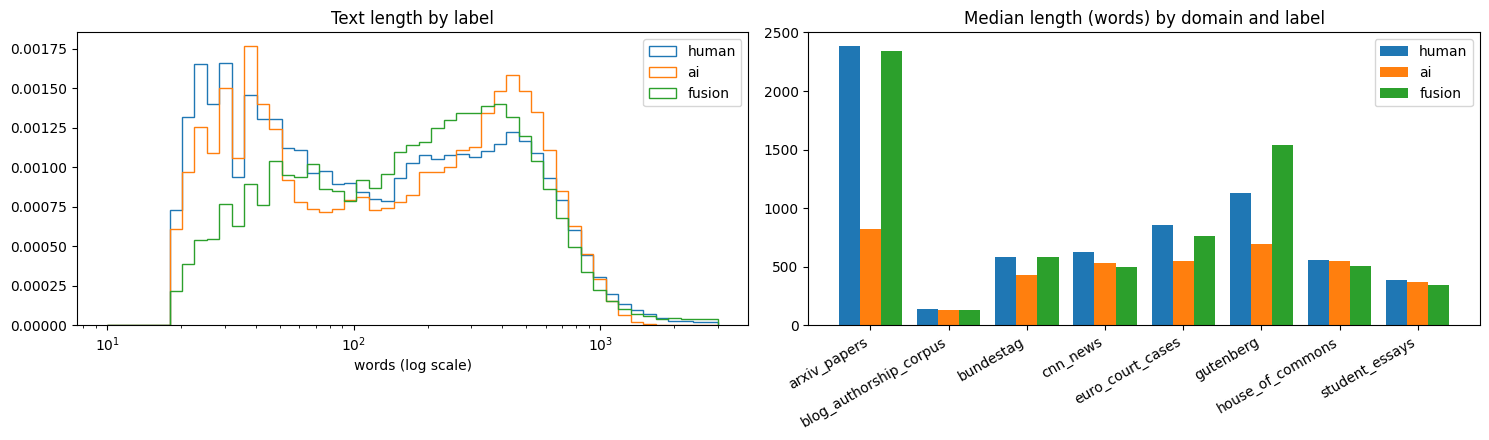

label,median words: human,median words: ai,median words: fusion
domain,,,
arxiv_papers,2382,824,2344
blog_authorship_corpus,137,129,128
bundestag,585,429,584
cnn_news,627,530,501
euro_court_cases,854,550,764
gutenberg,1131,696,1538
house_of_commons,554,547,509
student_essays,388,371,343


In [16]:
if RUN_EDA:
    hw.plot_lengths(train)
    plt.show()
    display(hw.length_table(train))

### 2.3 Length in encoder tokens
Share of texts that do not fit into one encoder window — the reason the encoder works on windows (chunks).

In [17]:
if RUN_EDA:
    display(hw.token_length_stats(train["text"], ENC_CFG.model_name, ENC_CFG.max_len))

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

,tokens: median,tokens: 90th pct,tokens: max,share > 512,mean windows of 512
xlm-roberta-base,667,1442,5708,0.645,2.06


### 2.4 Examples of each class

In [18]:
if RUN_EDA:
    hw.show_examples(train, n_chars=300)

[ai | de-DE | bundestag | 277 words]
  "Sehr geehrte Damen und Herren, liebe Kolleginnen und Kollegen, heute möchte ich mich zum Gesetzentwurf zur Vereinfachung des Meldewesens im Gastgewerbe äußern. Wie wir alle wissen, ist unsere deutsche Gastronomie ein essenzieller Teil unserer Wirtschaft und eines unverzichtbaren Aushängeschilds uns...

[ai | en-EN | student_essays | 475 words]
  The Benefits of Limiting Car Usage: A Path Towards Sustainable Urban Living In recent years, urban planners and environmentalists have increasingly advocated for reduced car usage as a means to address pressing environmental and social issues. Limiting car usage presents a multitude of benefits, inc...

[fusion | de-DE | bundestag | 886 words]
  Herr Präsident! Liebe Kolleginnen und Kollegen! Liebe Frau Ministerin, herzlichen Glückwunsch zum Amt! Es freut uns, eine Frau vom Fach zu haben. Das hätte manchen Männern auch ganz gut angestanden. Nichtsdestotrotz möchte ich darauf hinweisen, dass warme Worte al

### 2.5 Train vs. test distribution

In [19]:
if RUN_EDA:
    display(hw.compare_train_test(train, test))

,train,test
lang=en-EN,0.806,0.853
lang=de-DE,0.194,0.147
domain=student_essays,0.199,0.159
domain=bundestag,0.192,0.143
domain=cnn_news,0.163,0.197
domain=blog_authorship_corpus,0.149,0.178
domain=house_of_commons,0.117,0.118
domain=euro_court_cases,0.101,0.064
domain=arxiv_papers,0.052,0.067
domain=gutenberg,0.027,0.074


## 3. Groups of versions and the fixed validation split
A human text and its ai / fusion versions are near-duplicates and are always on the same side of the
train/test split. Groups are rebuilt from shared word 5-grams; the validation split keeps every group
whole, so validation mimics the test split.

In [20]:
train["group"] = hw.load_or_make_groups(train, paths, recompute=RECOMPUTE_GROUPS)
hw.group_composition(train)

find_groups: 272,352 texts -> 180,911 groups (linked pairs: 132,085, max group size: 656, 104s)


,groups,texts,max_size
labels in group,,,
ai,113817,118494,36
human+fusion,51177,130160,147
human,10873,10959,7
fusion,3882,4604,6
human+ai+fusion,1020,7604,656
ai+fusion,96,428,22
human+ai,46,103,5


In [21]:
tr, va = hw.load_or_make_split(train, paths, n_samples=SUBSAMPLE_N, recompute=RECOMPUTE_SPLIT)
hw.split_summary(tr, va)

,train,val
label=ai,0.451,0.451
label=fusion,0.307,0.301
label=human,0.242,0.248
lang=en-EN,0.805,0.791
lang=de-DE,0.195,0.209
domain=student_essays,0.201,0.185
domain=bundestag,0.193,0.207
domain=cnn_news,0.163,0.166
domain=blog_authorship_corpus,0.150,0.147
domain=house_of_commons,0.113,0.116


### 3.1 What makes fusion different
Every ai / fusion text that has a human version in its group is compared with that human version:
overlap of word 3-grams, share of sentences copied verbatim, relative length.

,jaccard_3gram,copied_sents,len_ratio
label,,,
ai,0.004,0.000,0.875
fusion,0.518,0.727,0.890


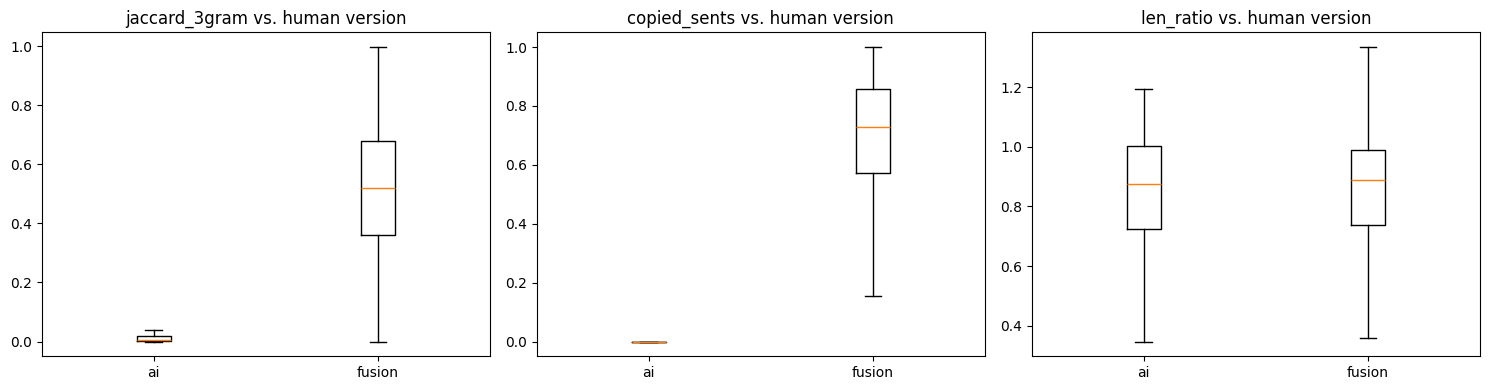

[human | student_essays | 493 words]
  Can multiple advice's benefit your choice on what to do? Most people believe that multiple advice's is better than just one advice. When people ask for an advice, they sometimes talk to more than one person. Asking for advice to multiple friends is better than one because of the following reasons. When someone asks more than one person they all can get a different response. The person who said the...

[ai | student_essays | 404 words]
  Beyond the Echo Chamber: Why Seeking Multiple Perspectives Enriches Your Decisions We live in an age of readily available information, with countless voices vying for our attention. Yet, when it comes to making important decisions, we often gravitate towards a single source – a trusted friend, a mentor figure, or even a seemingly authoritative online platform. While these sources can be valuable, ...

[fusion | student_essays | 401 words]
  Can multiple advice's benefit your choice on what to do? Most people believ

In [22]:
if RUN_EDA:
    cmp = hw.compare_with_human_version(train)
    display(cmp.groupby("label").median().round(3))
    hw.plot_human_version_comparison(cmp)
    plt.show()
    hw.show_group_example(train, n_chars=400)

## 4. Baseline: TF-IDF + linear models
TF-IDF is fitted on the train split only. Small grid search (feature set × model × C) on the fixed validation split.

In [ ]:
BL_DIR = paths.runs / BASELINE_RUN
if RUN_BASELINE:
    bl_grid, bl = hw.run_baseline(tr, va, test)
    bl_sub = hw.make_submission(test["id"], np.array(hw.LABELS)[bl["test_proba"].argmax(1)], sample)
    hw.save_run(BL_DIR, bl["metrics"], bl["config"], va["id"], bl["val_proba"],
                test["id"], bl["test_proba"], bl_sub)
    bl_grid.to_csv(BL_DIR / "grid.csv", index=False)

bl_run = hw.load_run(BL_DIR)
pd.read_csv(BL_DIR / "grid.csv")

TF-IDF char: 300,000 features (281s)
TF-IDF word: 300,000 features (80s)
  word       logreg  C=1.0   macro-F1=0.8379 (55.7s)
  word       logreg  C=10.0  macro-F1=0.8561 (54.7s)
  word       linsvc  C=0.1   macro-F1=0.8148 (5.0s)
  word       linsvc  C=1.0   macro-F1=0.8330 (7.8s)
  char       logreg  C=1.0   macro-F1=0.8605 (179.9s)
  char       logreg  C=10.0  macro-F1=0.8699 (169.6s)
  char       linsvc  C=0.1   macro-F1=0.8342 (20.4s)
  char       linsvc  C=1.0   macro-F1=0.8556 (38.0s)
  word+char  logreg  C=1.0   macro-F1=0.8703 (175.4s)
  word+char  logreg  C=10.0  macro-F1=0.8758 (261.5s)


In [ ]:
bl_per_class, bl_by, _ = hw.run_report(bl_run, va, f"Baseline {bl_run['config']}")
plt.show()
display(bl_per_class, bl_by)

## 5. Encoder: fine-tuned multilingual transformer
Long texts are split into overlapping windows of `max_len` tokens. Training sees a random window of
each text (a new one every epoch); prediction averages the probabilities of up to `max_eval_windows`
windows that cover the text. The best epoch is selected on the same validation split as the baseline.

If the Colab session dies, rerun this cell: training resumes from the last finished epoch.

In [ ]:
ENC_DIR = paths.runs / ENCODER_RUN
if RUN_ENCODER:
    enc = hw.train_encoder(tr, va, test, ENC_CFG, ENC_DIR)
    enc_sub = hw.make_submission(test["id"], np.array(hw.LABELS)[enc["test_proba"].argmax(1)], sample)
    hw.save_run(ENC_DIR, enc["metrics"], enc["config"], va["id"], enc["val_proba"],
                test["id"], enc["test_proba"], enc_sub)

enc_run = hw.load_run(ENC_DIR)
pd.DataFrame(enc_run["metrics"]["history"])

In [ ]:
enc_per_class, enc_by, _ = hw.run_report(enc_run, va, f"Encoder {ENC_CFG.model_name}")
plt.show()
display(enc_per_class, enc_by)

## 6. Baseline vs. encoder (same validation split)
Submission files: `runs/<run name>/submission.csv` on Google Drive.

In [ ]:
hw.compare_runs(paths, [BASELINE_RUN, ENCODER_RUN], va)